# 6. Candidate Review and Cluster Profiling

Review a small shortlist in original units, test sensitivity, and record a reasoned model decision. A final selection is deliberately not prefilled.

Adapted from the original group project's size/profile comparisons, with dynamic reference statistics and explicit customer-ID alignment. Shopping periods are summarized as category percentages rather than averages of integer codes. Card ownership is not treated as loyalty, complaint incidence is not equated with satisfaction, and title-derived degree flags are only a proxy.

Run Notebook 5 first. Keep final assignment of deferred customers as a separate, documented task before basket-level campaigns.

In [21]:
from pathlib import Path
import sys
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib
from IPython.display import display

project_root = Path.cwd()
if project_root.name == "notebooks":
    project_root = project_root.parent
sys.path.insert(0, str(project_root))
feature_dir = project_root / "data" / "features"
cluster_dir = project_root / "models" / "clustering"
table_dir = project_root / "reports" / "tables" / "clustering"
figure_dir = project_root / "reports" / "figures" / "clustering"
for directory in [cluster_dir, table_dir, figure_dir]:
    directory.mkdir(parents=True, exist_ok=True)

from utils.clustering_functions import subsample_stability
from utils.profiling_functions import build_cluster_profiles, plot_cluster_sizes, plot_relative_profiles

summary = pd.read_csv(table_dir / "kmeans_summary.csv")
labels = pd.read_csv(cluster_dir / "candidate_assignments.csv", index_col="customer_id")
models = joblib.load(cluster_dir / "candidate_models.joblib")
customer_table = pd.read_csv(feature_dir / "customer_profiles.csv", index_col="customer_id")
assert labels.index.is_unique and customer_table.index.is_unique
customers = customer_table.loc[labels.index].copy()
population = pd.read_csv(feature_dir / "customer_population.csv")
spend_columns = [c for c in customers if c.startswith("spend_per_year_")]
display(summary.round(3))

,representation,k,silhouette_mean,silhouette_sd,inertia_mean,db_mean,min_cluster_pct,max_cluster_pct,clusters_found_min,any_iteration_limit,mean_seconds,seed_ari_mean,seed_ari_min,candidate_id
0,log_pca,2,0.235,0.001,248576.923,1.525,48.168,51.832,2,False,0.392,0.983,0.975,log_pca__k2
1,log_pca,3,0.250,0.000,208031.637,1.349,13.006,47.727,3,False,0.460,0.991,0.987,log_pca__k3
2,log_pca,4,0.227,0.000,177018.698,1.390,13.000,46.846,4,False,0.519,0.996,0.994,log_pca__k4
3,log_pca,5,0.223,0.000,163229.514,1.480,11.223,40.712,5,False,0.647,0.997,0.995,log_pca__k5
4,log_pca,6,0.215,0.000,150882.171,1.519,10.535,32.131,6,False,0.738,0.995,0.993,log_pca__k6
5,log_pca,7,0.204,0.000,140724.941,1.502,7.925,21.889,7,False,0.742,0.983,0.974,log_pca__k7
6,log_pca,8,0.189,0.001,135729.354,1.596,3.366,21.097,8,False,0.991,0.748,0.625,log_pca__k8
7,log_pca,9,0.188,0.000,130990.316,1.563,3.239,20.154,9,False,1.252,0.968,0.952,log_pca__k9
8,log_pca,10,0.179,0.005,126845.462,1.662,3.005,18.793,10,False,1.399,0.864,0.796,log_pca__k10
9,log_scaled,2,0.220,0.000,275834.322,1.616,47.979,52.021,2,False,0.386,0.991,0.987,log_scaled__k2


## 1. Set a shortlist
The shortlist compares three levels of segmentation detail using the
log-scaled representation, plus a six-cluster PCA alternative.

log_scaled__k3


,customers,customer_pct,share_of_recorded_annual_spending_pct
cluster,,,
0,13397,39.74,19.94
1,4373,12.97,5.57
2,15945,47.29,74.49


,spend_per_year_groceries,spend_per_year_electronics,spend_per_year_vegetables,spend_per_year_nonalcohol_drinks,spend_per_year_alcohol_drinks,spend_per_year_meat,spend_per_year_fish,spend_per_year_hygiene,spend_per_year_petfood,spend_per_year_videogames
cluster,,,,,,,,,,
0,1201.75,89.00,26.53,26.43,36.75,71.68,47.76,47.50,24.27,17.90
1,935.62,181.92,184.67,36.75,36.86,4.67,6.62,65.21,22.57,18.55
2,3008.25,524.07,59.50,64.92,131.08,130.08,126.73,81.10,39.67,55.62


total_annual_spending          pct_prod_in_promotion           age  \
                         mean   median                  mean median   mean   
cluster                                                                      
0                     1986.29  1703.57                  0.44   0.42  55.09   
1                     1699.71  1508.70                  0.10   0.10  57.48   
2                     6235.69  4484.60                  0.24   0.20  53.39   

               child_home        customer_lifetime         \
        median       mean median              mean median   
cluster                                                     
0         54.0       2.11    2.0             12.50   13.0   
1         57.0       1.28    1.0             10.78   11.0   
2         54.0       2.24    2.0              8.77    9.0   

        distinct_stores_visited        lifetime_total_distinct_products         
                           mean median                             mean median  
cluster                                                                         
0                          3.33    3.0                           139.66   85.0  
1                          3.13    3.0                            81.49   81.0  
2                          2.47    2.0                           192.22  172.0

,loyalty_card,complained,degree,male
cluster,,,,
0,74.3,69.8,40.1,50.1
1,60.1,64.8,65.0,51.1
2,65.0,52.4,62.2,50.2


typical_time,0,1,2
cluster,,,
0,46.3,35.9,17.8
1,34.6,42.8,22.6
2,47.8,31.0,21.1


,spend_per_year_groceries,spend_per_year_electronics,spend_per_year_vegetables,spend_per_year_nonalcohol_drinks,spend_per_year_alcohol_drinks,spend_per_year_meat,spend_per_year_fish,spend_per_year_hygiene,spend_per_year_petfood,spend_per_year_videogames
cluster,,,,,,,,,,
0,0.689,0.087,0.026,0.018,0.027,0.053,0.033,0.035,0.019,0.014
1,0.573,0.137,0.142,0.028,0.029,0.004,0.005,0.050,0.017,0.014
2,0.652,0.159,0.019,0.018,0.035,0.034,0.033,0.023,0.011,0.017


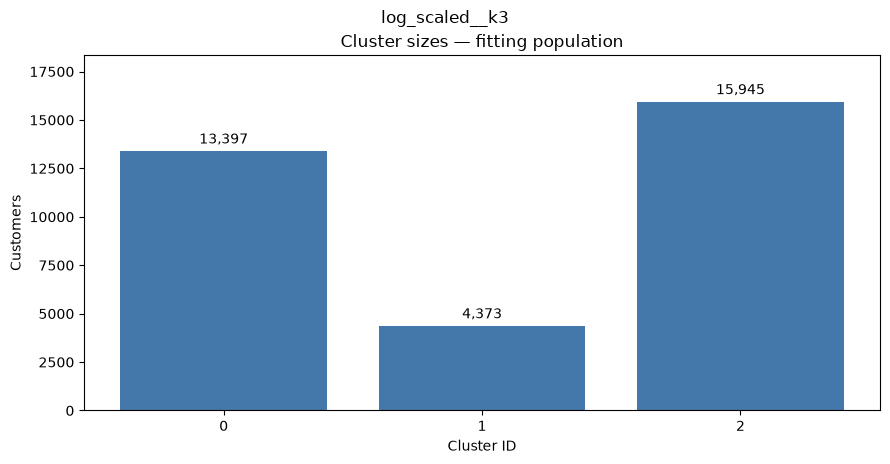

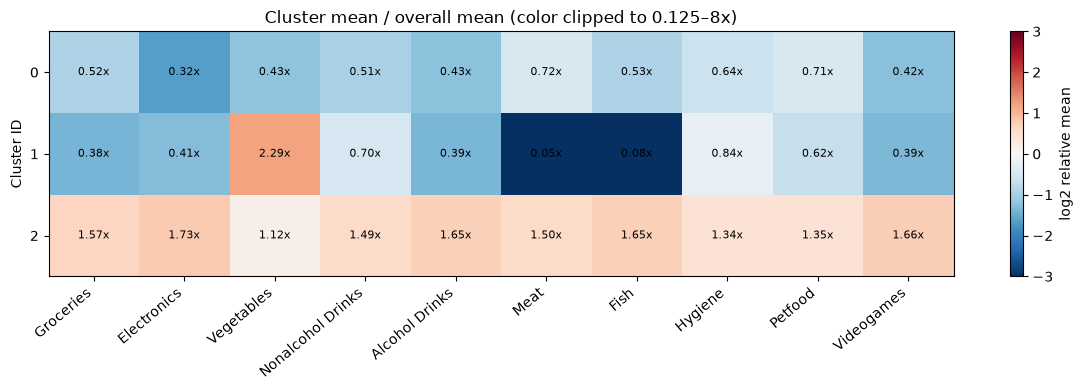

log_scaled__k5


,customers,customer_pct,share_of_recorded_annual_spending_pct
cluster,,,
0,4914,14.58,39.44
1,4370,12.96,5.58
2,3755,11.14,13.72
3,6928,20.55,7.72
4,13748,40.78,33.54


,spend_per_year_groceries,spend_per_year_electronics,spend_per_year_vegetables,spend_per_year_nonalcohol_drinks,spend_per_year_alcohol_drinks,spend_per_year_meat,spend_per_year_fish,spend_per_year_hygiene,spend_per_year_petfood,spend_per_year_videogames
cluster,,,,,,,,,,
0,5773.58,870.39,129.47,110.00,213.88,219.76,221.05,151.28,69.33,92.73
1,937.94,181.93,184.83,36.74,36.81,4.67,6.62,65.25,22.57,18.55
2,2536.75,941.30,16.80,61.33,128.29,106.14,107.18,21.25,35.56,114.12
3,974.25,40.31,27.25,16.00,18.04,66.52,31.83,37.67,25.09,13.50
4,1992.91,287.15,41.67,45.40,81.31,95.26,85.95,73.50,27.47,28.88


total_annual_spending          pct_prod_in_promotion           age  \
                         mean   median                  mean median   mean   
cluster                                                                      
0                    10711.26  8301.86                  0.25   0.19  48.62   
1                     1703.81  1509.61                  0.10   0.10  57.44   
2                     4877.03  4193.18                  0.26   0.24  54.92   
3                     1487.79  1302.41                  0.53   0.57  54.37   
4                     3256.45  2857.80                  0.28   0.22  55.85   

               child_home        customer_lifetime         \
        median       mean median              mean median   
cluster                                                     
0         47.0       2.29    2.0              5.36    5.0   
1         57.0       1.28    1.0             10.78   11.0   
2         55.0       0.91    1.0              8.69    8.0   
3         54.0       1.76    2.0             11.78   11.0   
4         56.0       2.70    2.0             12.13   12.0   

        distinct_stores_visited        lifetime_total_distinct_products         
                           mean median                             mean median  
cluster                                                                         
0                          2.49    2.0                           205.33  185.0  
1                          3.13    3.0                            81.45   81.0  
2                          1.66    1.0                           127.14  111.0  
3                          3.53    4.0                            81.38   58.0  
4                          2.99    3.0                           209.95  205.0

,loyalty_card,complained,degree,male
cluster,,,,
0,66.6,47.5,64.2,50.0
1,60.1,64.9,65.1,51.1
2,51.1,61.1,65.0,49.6
3,78.1,68.1,30.6,50.3
4,70.7,60.8,55.1,50.3


typical_time,0,1,2
cluster,,,
0,47.2,32.7,20.1
1,34.6,42.8,22.6
2,35.2,27.7,37.0
3,41.5,39.1,19.4
4,53.2,32.0,14.8


,spend_per_year_groceries,spend_per_year_electronics,spend_per_year_vegetables,spend_per_year_nonalcohol_drinks,spend_per_year_alcohol_drinks,spend_per_year_meat,spend_per_year_fish,spend_per_year_hygiene,spend_per_year_petfood,spend_per_year_videogames
cluster,,,,,,,,,,
0,0.667,0.145,0.023,0.017,0.033,0.033,0.032,0.025,0.011,0.014
1,0.573,0.137,0.142,0.028,0.028,0.004,0.005,0.050,0.017,0.014
2,0.581,0.252,0.007,0.017,0.037,0.029,0.029,0.007,0.010,0.031
3,0.711,0.052,0.033,0.016,0.021,0.063,0.030,0.036,0.024,0.014
4,0.672,0.122,0.021,0.020,0.035,0.040,0.035,0.031,0.012,0.012


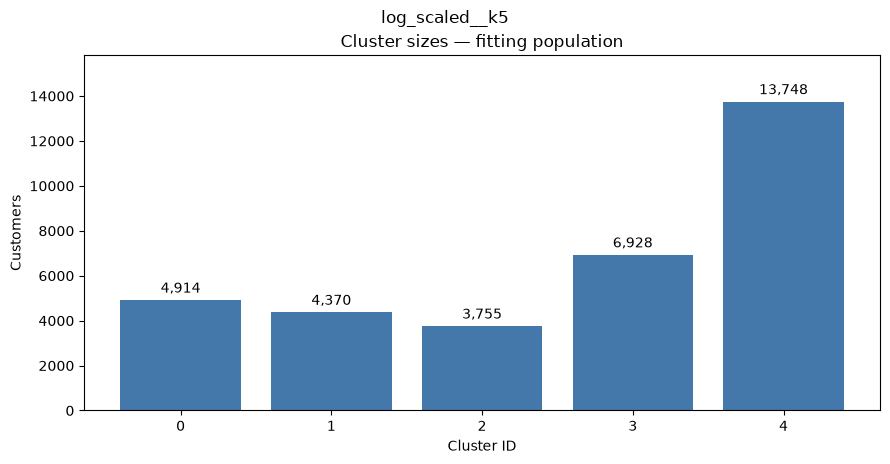

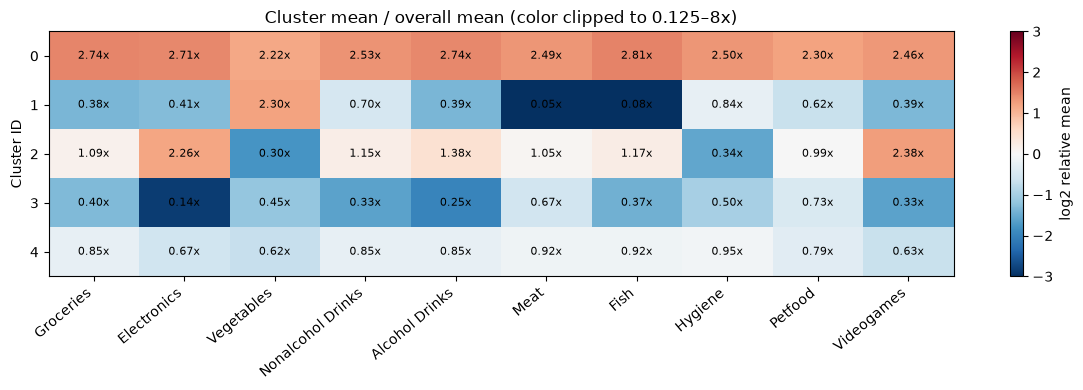

log_scaled__k6


,customers,customer_pct,share_of_recorded_annual_spending_pct
cluster,,,
0,10876,32.26,26.78
1,3521,10.44,13.17
2,5314,15.76,4.99
3,5137,15.24,11.97
4,4496,13.34,37.50
5,4371,12.96,5.58


,spend_per_year_groceries,spend_per_year_electronics,spend_per_year_vegetables,spend_per_year_nonalcohol_drinks,spend_per_year_alcohol_drinks,spend_per_year_meat,spend_per_year_fish,spend_per_year_hygiene,spend_per_year_petfood,spend_per_year_videogames
cluster,,,,,,,,,,
0,1920.15,317.46,49.00,45.76,93.72,97.70,92.00,68.50,26.29,30.54
1,2574.88,1014.91,16.18,63.15,130.50,107.75,107.56,22.00,36.57,121.50
2,859.10,33.15,27.10,13.71,15.00,63.36,28.11,32.64,23.50,11.80
3,2051.27,152.93,28.45,39.10,46.66,90.14,66.00,80.33,33.58,24.18
4,5968.40,916.41,134.50,116.15,224.17,228.53,230.58,159.06,71.75,96.42
5,939.35,181.93,184.82,36.76,36.80,4.67,6.62,65.27,22.57,18.56


total_annual_spending          pct_prod_in_promotion           age  \
                         mean   median                  mean median   mean   
cluster                                                                      
0                     3286.26  2818.25                  0.18   0.16  56.77   
1                     4992.96  4274.80                  0.26   0.24  55.13   
2                     1254.57  1150.05                  0.48   0.49  55.04   
3                     3110.82  2759.00                  0.64   0.63  52.46   
4                    11132.11  8595.85                  0.25   0.19  48.06   
5                     1704.99  1511.00                  0.10   0.10  57.44   

               child_home        customer_lifetime         \
        median       mean median              mean median   
cluster                                                     
0         57.0       2.96    2.0             12.75   13.0   
1         55.0       0.84    1.0              8.49    8.0   
2         54.0       1.74    2.0             12.33   12.0   
3         52.0       1.80    2.0              9.76    9.0   
4         46.0       2.31    2.0              5.14    5.0   
5         57.0       1.28    1.0             10.78   11.0   

        distinct_stores_visited        lifetime_total_distinct_products         
                           mean median                             mean median  
cluster                                                                         
0                          2.86    3.0                           219.85  210.0  
1                          1.60    1.0                           123.53  109.0  
2                          3.57    4.0                            70.36   55.0  
3                          3.32    3.0                           155.96  116.0  
4                          2.50    2.0                           208.01  189.0  
5                          3.14    3.0                            81.47   81.0

,loyalty_card,complained,degree,male
cluster,,,,
0,70.7,54.6,59.2,50.3
1,50.2,62.9,65.3,49.0
2,79.4,66.8,29.1,49.8
3,71.4,74.7,41.3,50.8
4,66.3,48.1,64.1,50.4
5,60.2,64.9,65.1,51.1


typical_time,0,1,2
cluster,,,
0,55.7,30.9,13.5
1,34.6,27.3,38.1
2,40.6,39.6,19.8
3,44.1,36.0,20.0
4,47.6,32.8,19.6
5,34.5,42.9,22.6


,spend_per_year_groceries,spend_per_year_electronics,spend_per_year_vegetables,spend_per_year_nonalcohol_drinks,spend_per_year_alcohol_drinks,spend_per_year_meat,spend_per_year_fish,spend_per_year_hygiene,spend_per_year_petfood,spend_per_year_videogames
cluster,,,,,,,,,,
0,0.657,0.131,0.022,0.020,0.038,0.041,0.038,0.029,0.011,0.013
1,0.573,0.261,0.006,0.017,0.037,0.029,0.029,0.007,0.010,0.032
2,0.707,0.048,0.036,0.015,0.021,0.067,0.031,0.036,0.025,0.015
3,0.720,0.086,0.018,0.017,0.024,0.042,0.029,0.035,0.017,0.012
4,0.667,0.145,0.023,0.017,0.033,0.033,0.032,0.025,0.011,0.014
5,0.573,0.137,0.142,0.028,0.028,0.004,0.005,0.050,0.017,0.014


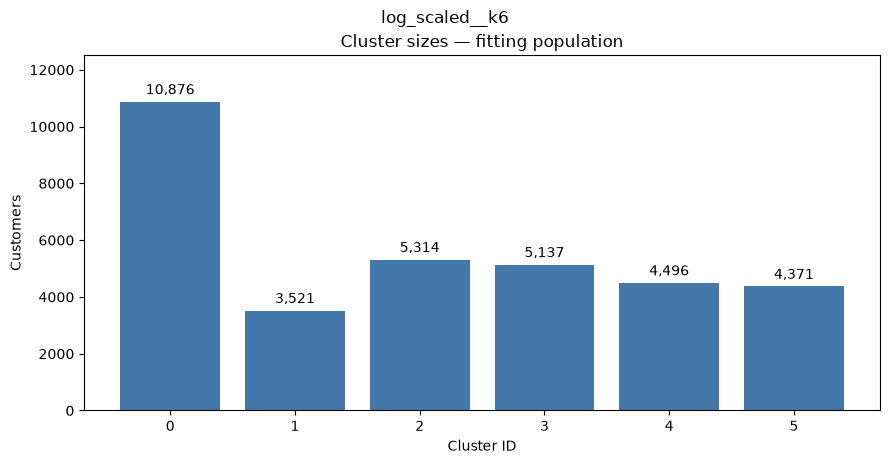

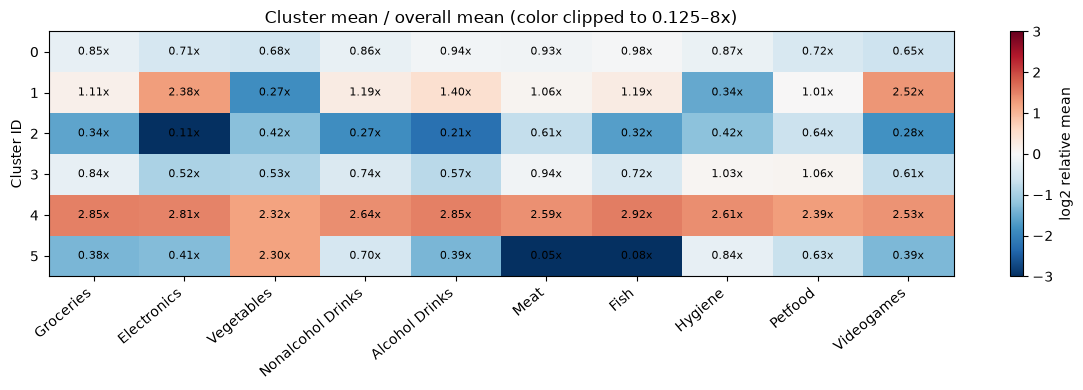

log_pca__k6


,customers,customer_pct,share_of_recorded_annual_spending_pct
cluster,,,
0,5278,15.65,4.95
1,10821,32.10,26.68
2,4380,12.99,5.59
3,4477,13.28,37.39
4,5206,15.44,12.06
5,3553,10.54,13.33


,spend_per_year_groceries,spend_per_year_electronics,spend_per_year_vegetables,spend_per_year_nonalcohol_drinks,spend_per_year_alcohol_drinks,spend_per_year_meat,spend_per_year_fish,spend_per_year_hygiene,spend_per_year_petfood,spend_per_year_videogames
cluster,,,,,,,,,,
0,858.03,33.37,26.99,13.60,15.00,62.97,28.27,32.36,23.43,11.67
1,1919.90,317.62,49.00,45.83,94.07,97.69,92.50,68.67,26.23,30.67
2,938.87,181.92,184.68,36.71,36.78,4.67,6.60,65.26,22.57,18.56
3,5968.80,917.17,134.50,116.20,224.43,229.12,231.00,159.50,72.00,96.57
4,2048.45,150.50,28.46,39.11,46.00,90.63,65.25,80.69,33.61,24.20
5,2586.17,1016.14,16.44,62.78,129.40,108.00,107.71,21.86,36.67,120.20


total_annual_spending          pct_prod_in_promotion           age  \
                         mean   median                  mean median   mean   
cluster                                                                      
0                     1250.63  1148.84                  0.48   0.49  54.91   
1                     3290.93  2817.71                  0.18   0.16  56.78   
2                     1704.51  1511.04                  0.10   0.10  57.43   
3                    11146.93  8598.75                  0.25   0.19  48.01   
4                     3091.32  2749.67                  0.63   0.63  52.59   
5                     5008.50  4293.25                  0.26   0.24  55.22   

               child_home        customer_lifetime         \
        median       mean median              mean median   
cluster                                                     
0         54.0       1.75    2.0             12.37   12.0   
1         57.0       2.96    2.0             12.75   13.0   
2         57.0       1.28    1.0             10.78   11.0   
3         46.0       2.31    2.0              5.12    5.0   
4         52.0       1.81    2.0              9.76    9.0   
5         55.0       0.86    1.0              8.53    8.0   

        distinct_stores_visited        lifetime_total_distinct_products         
                           mean median                             mean median  
cluster                                                                         
0                          3.55    4.0                            70.25   55.0  
1                          2.85    3.0                           220.04  210.0  
2                          3.14    3.0                            81.56   81.0  
3                          2.50    2.0                           207.74  189.0  
4                          3.34    3.0                           155.50  114.0  
5                          1.61    1.0                           124.94  110.0

,loyalty_card,complained,degree,male
cluster,,,,
0,79.0,67.1,28.9,49.9
1,70.6,54.4,59.3,50.3
2,60.2,64.9,65.1,51.1
3,66.4,48.2,64.2,50.5
4,72.0,74.4,41.5,50.5
5,50.3,62.9,65.2,49.1


typical_time,0,1,2
cluster,,,
0,41.1,39.3,19.6
1,55.5,30.9,13.5
2,34.6,42.8,22.6
3,47.6,32.7,19.7
4,43.8,36.3,20.0
5,35.0,27.4,37.6


,spend_per_year_groceries,spend_per_year_electronics,spend_per_year_vegetables,spend_per_year_nonalcohol_drinks,spend_per_year_alcohol_drinks,spend_per_year_meat,spend_per_year_fish,spend_per_year_hygiene,spend_per_year_petfood,spend_per_year_videogames
cluster,,,,,,,,,,
0,0.707,0.049,0.036,0.015,0.021,0.066,0.031,0.035,0.025,0.014
1,0.656,0.131,0.022,0.020,0.038,0.041,0.038,0.029,0.011,0.013
2,0.573,0.137,0.142,0.028,0.028,0.004,0.005,0.050,0.017,0.014
3,0.667,0.145,0.023,0.017,0.033,0.033,0.032,0.025,0.011,0.014
4,0.721,0.085,0.018,0.017,0.023,0.042,0.028,0.035,0.017,0.012
5,0.574,0.261,0.006,0.017,0.036,0.029,0.029,0.007,0.010,0.031


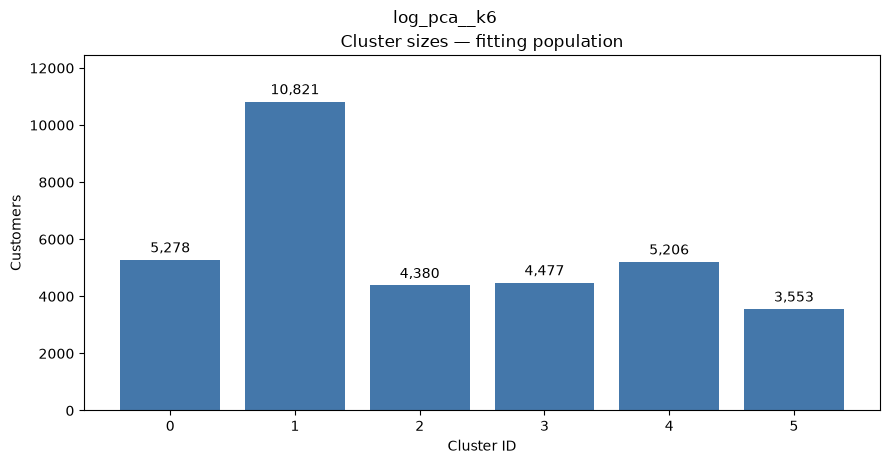

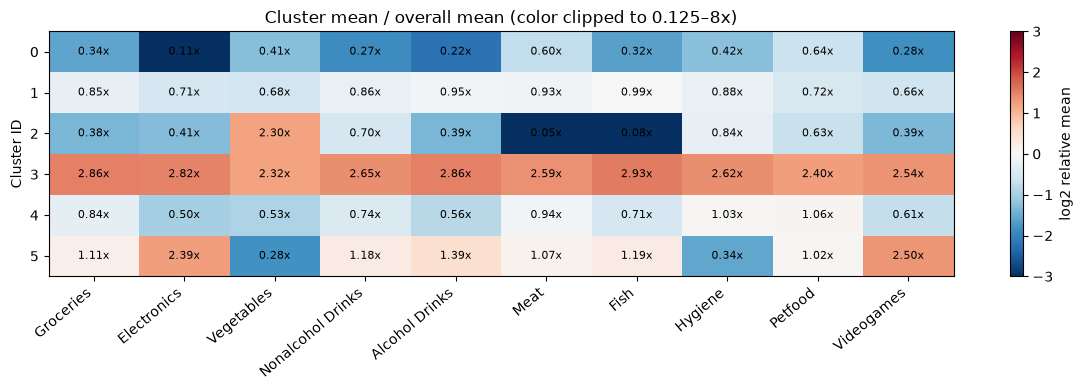

In [22]:
SHORTLIST = [
    "log_scaled__k3",       # Coarse, stable benchmark
    "log_scaled__k5",       # Intermediate segmentation
    "log_scaled__k6",       # More detailed, promising profiles
    "log_pca__k6",          # Compression comparison at the same k
]
assert set(SHORTLIST).issubset(labels.columns)
profile_tables = {}
for candidate_id in SHORTLIST:
    tables = build_cluster_profiles(customers, labels[candidate_id], spend_columns)
    profile_tables[candidate_id] = tables
    print(candidate_id)
    display(tables["sizes"].round(2))
    display(tables["spending_medians"].round(2))
    display(tables["overview"].round(2))
    display(tables["binary_rates_pct"].round(1))
    display(tables["shopping_time_pct"].round(1))
    display(tables["mean_category_shares"].round(3))
    for name, fig in [("sizes", plot_cluster_sizes(tables["sizes"])),
                      ("relative_spending", plot_relative_profiles(tables["relative_spending_means"]))]:
        fig.suptitle(candidate_id, y=1.02)
        fig.savefig(figure_dir / f"{candidate_id}_{name}.png", dpi=160, bbox_inches="tight")
        plt.show()

## 2. Customer-subsampling sensitivity
Refit on 80% subsets, then predict all fitting customers and compare to the candidate reference using ARI. Feature preparation is held fixed. This is not full-pipeline bootstrap validation, temporal validation, or evidence of true segment labels. Review per-cluster changes if aggregate ARI hides instability of small groups.

In [23]:
stability_tables = []
for candidate_id in SHORTLIST:
    representation = candidate_id.rsplit("__k", 1)[0]
    X = pd.read_csv(feature_dir / f"{representation}.csv", index_col="customer_id")
    assert X.index.equals(labels.index)
    result = subsample_stability(X, models[candidate_id], repeats=5, fraction=.8)
    result["candidate_id"] = candidate_id
    stability_tables.append(result)
subsample_results = pd.concat(stability_tables, ignore_index=True)
display(subsample_results.groupby("candidate_id")["ari_to_reference"].agg(["min", "mean", "std"]).round(3))
subsample_results.to_csv(table_dir / "shortlist_subsample_stability.csv", index=False)

,min,mean,std
candidate_id,,,
log_pca__k6,0.980,0.985,0.003
log_scaled__k3,0.977,0.991,0.009
log_scaled__k5,0.536,0.901,0.204
log_scaled__k6,0.975,0.982,0.005


## 3. Outlier-flag composition by cluster
Flags are diagnostic and must not become fitting features. Compare flagged proportions to see whether a candidate isolates high-spending customers or mixes them into broader profiles. These proportions are not error rates.

In [24]:
flags = pd.read_csv(project_root / "data" / "preprocessed" / "customer_outlier_flags.csv").set_index("customer_id")
flag_columns = [c for c in ["iqr_outlier", "consensus_outlier"] if c in flags]
for candidate_id in SHORTLIST:
    diagnostic = labels[[candidate_id]].join(flags[flag_columns], validate="one_to_one")
    for column in flag_columns:
        diagnostic[column] = diagnostic[column].astype(str).str.lower().map({"true": 1., "false": 0.})
    print(candidate_id)
    display((diagnostic.groupby(candidate_id)[flag_columns].mean() * 100).round(2))

log_scaled__k3


,iqr_outlier,consensus_outlier
log_scaled__k3,,
0,0.00,0.01
1,0.02,0.05
2,3.29,5.45


log_scaled__k5


,iqr_outlier,consensus_outlier
log_scaled__k5,,
0,10.38,17.01
1,0.00,0.05
2,0.29,0.69
3,0.00,0.00
4,0.03,0.07


log_scaled__k6


,iqr_outlier,consensus_outlier
log_scaled__k6,,
0,0.02,0.06
1,0.31,0.77
2,0.00,0.00
3,0.08,0.18
4,11.30,18.42
5,0.00,0.05


log_pca__k6


,iqr_outlier,consensus_outlier
log_pca__k6,,
0,0.00,0.00
1,0.02,0.06
2,0.00,0.05
3,11.35,18.54
4,0.06,0.13
5,0.34,0.76


## 4. Record a comparison, not a fabricated ranking
Fill the notes after inspecting results. No weighted automatic composite score is used. Compare internal scores within their own feature space and weigh business distinctions, cluster sizes, seed sensitivity, and subsampling sensitivity together.

Do not penalize a small segment solely for being small. Do not select a model just because the old project had eight segments. If baseline limitations remain, add a targeted SOM or prototype-hierarchical benchmark before finalizing.

In [25]:
comparison = summary[summary["candidate_id"].isin(SHORTLIST)].copy()
subsample_summary = subsample_results.groupby("candidate_id")["ari_to_reference"].agg(
    subsample_ari_mean="mean", subsample_ari_min="min")
comparison = comparison.merge(subsample_summary, on="candidate_id")
candidate_notes = {
    "log_scaled__k3": {
        "business_distinctions": (
            "Provides a broad spending separation and a distinct "
            "vegetable-focused group."
        ),
        "limitations": (
            "The largest cluster contains 47.29% of fitting customers, "
            "combining purchasing profiles that are separated at k=6."
        ),
        "decision_notes": (
            "Retained as a coarse benchmark, but not selected for "
            "the more detailed marketing segmentation."
        ),
    },

    "log_scaled__k5": {
        "business_distinctions": (
            "Identifies high-spending, electronics/gaming, vegetable-focused, "
            "low-spending and broad moderate-spending groups."
        ),
        "limitations": (
            "Minimum subsampling ARI falls to 0.536, indicating substantial "
            "assignment changes in at least one refit."
        ),
        "decision_notes": (
            "Not selected because the six-cluster alternatives provide "
            "more consistent subsampling results and useful additional detail."
        ),
    },

    "log_scaled__k6": {
        "business_distinctions": (
            "Separates overall spending intensity, electronics/gaming "
            "purchasing, vegetable-focused spending, and different levels "
            "of promotion purchasing."
        ),
        "limitations": (
            "Annual spending remains associated with tenure. "
            "Stability checks hold feature preparation fixed, and "
            "zero-tenure customers remain unassigned."
        ),
        "decision_notes": (
            "Selected: interpretable original-feature representation, "
            "distinct profiles, minimum seed ARI about 0.993 and "
            "minimum subsampling ARI about 0.975."
        ),
    },

    "log_pca__k6": {
        "business_distinctions": (
            "Produces six profiles closely resembling the full "
            "log-scaled solution."
        ),
        "limitations": (
            "Adds a compression layer without an evident practical "
            "advantage in the displayed profiles."
        ),
        "decision_notes": (
            "Retained as a strong alternative. Its slightly higher "
            "subsampling agreement alone does not establish superiority."
        ),
    },
}

for column in [
    "business_distinctions",
    "limitations",
    "decision_notes",
]:
    comparison[column] = comparison["candidate_id"].map(
        {
            candidate_id: notes[column]
            for candidate_id, notes in candidate_notes.items()
        }
    )

comparison["decision"] = comparison["candidate_id"].map({
    "log_scaled__k3": "Coarse benchmark",
    "log_scaled__k5": "Not selected",
    "log_scaled__k6": "Selected",
    "log_pca__k6": "Alternative",
})

review_columns = [
    "candidate_id",
    "silhouette_mean",
    "seed_ari_min",
    "subsample_ari_mean",
    "subsample_ari_min",
    "decision",
    "business_distinctions",
    "limitations",
    "decision_notes",
]

display(
    comparison[review_columns]
    .round(3)
    .style
    .set_properties(**{
        "white-space": "normal",
        "text-align": "left",
    })
)

comparison.to_csv(
    table_dir / "shortlist_review_completed.csv",
    index=False,
)


,candidate_id,silhouette_mean,seed_ari_min,subsample_ari_mean,subsample_ari_min,decision,business_distinctions,limitations,decision_notes
0,log_pca__k6,0.215000,0.993000,0.985000,0.980000,Alternative,Produces six profiles closely resembling the full log-scaled solution.,Adds a compression layer without an evident practical advantage in the displayed profiles.,Retained as a strong alternative. Its slightly higher subsampling agreement alone does not establish superiority.
1,log_scaled__k3,0.232000,0.984000,0.991000,0.977000,Coarse benchmark,Provides a broad spending separation and a distinct vegetable-focused group.,"The largest cluster contains 47.29% of fitting customers, combining purchasing profiles that are separated at k=6.","Retained as a coarse benchmark, but not selected for the more detailed marketing segmentation."
2,log_scaled__k5,0.203000,0.991000,0.901000,0.536000,Not selected,"Identifies high-spending, electronics/gaming, vegetable-focused, low-spending and broad moderate-spending groups.","Minimum subsampling ARI falls to 0.536, indicating substantial assignment changes in at least one refit.",Not selected because the six-cluster alternatives provide more consistent subsampling results and useful additional detail.
3,log_scaled__k6,0.195000,0.993000,0.982000,0.975000,Selected,"Separates overall spending intensity, electronics/gaming purchasing, vegetable-focused spending, and different levels of promotion purchasing.","Annual spending remains associated with tenure. Stability checks hold feature preparation fixed, and zero-tenure customers remain unassigned.","Selected: interpretable original-feature representation, distinct profiles, minimum seed ARI about 0.993 and minimum subsampling ARI about 0.975."


## 5. Optional explicit selection and export
Leave the selection empty until the comparison is reviewed. This cell exports nothing final by default. After choosing a candidate, record a reason in your notebook, not only in a spreadsheet.

The all-customer register retains missing cluster labels for deferred/excluded customers. It is NOT the complete assignment deliverable and must not be used as if every customer had a segment. No uncertain annualized input is silently passed through the model.

In [26]:
SELECTED_CANDIDATE =  "log_scaled__k6"
SELECTION_REASON = (
    "Selected as the working segmentation for positive-tenure customers. "
    "The six-cluster log-scaled solution provides distinct spending and "
    "promotion-purchasing profiles, with minimum seed-pair ARI of approximately "
    "0.993 and minimum subsampling ARI of approximately 0.975. "
    "The three-cluster solution is useful but too coarse for the intended "
    "targeted marketing analysis. The five-cluster solution showed a "
    "substantial subsampling instability. The six-cluster PCA alternative "
    "produced similar profiles without a clear practical advantage sufficient "
    "to justify the additional compression layer. "
    "Zero-tenure customers remain pending and are not assigned automatically."
)

SEGMENT_NAMES = {
    0: "Established Multi-Category Shoppers",
    1: "Electronics and Gaming Shoppers",
    2: "Low-Spending, Promotion-Oriented Shoppers",
    3: "Promotion-Heavy Regular Shoppers",
    4: "High-Spending Multi-Category Shoppers",
    5: "Vegetable-Focused Shoppers",
}

if SELECTED_CANDIDATE is None:
    print("No final candidate selected. All exported search results remain exploratory.")
else:
    assert SELECTED_CANDIDATE in SHORTLIST
    assert SELECTION_REASON.strip(), "Record the evidence for selection."
    chosen_labels = labels[SELECTED_CANDIDATE].rename("cluster")
    chosen_profiles = build_cluster_profiles(customers, chosen_labels, spend_columns)
    destination = table_dir / "selected_profiles"
    destination.mkdir(parents=True, exist_ok=True)
    for name, table in chosen_profiles.items():
        table.to_csv(destination / f"{name}.csv")
    chosen_labels.to_csv(cluster_dir / "selected_fitting_assignments.csv", index_label="customer_id")
    joblib.dump(models[SELECTED_CANDIDATE], cluster_dir / "selected_kmeans.joblib")

    register = population.merge(chosen_labels.reset_index(), on="customer_id", how="left", validate="one_to_one")
    register["assignment_status"] = np.where(register["cluster"].notna(), "assigned_fitting", "pending_review")
    register["segment_name"] = register["cluster"].map(SEGMENT_NAMES)
    register.to_csv(cluster_dir / "customer_assignment_register_INCOMPLETE.csv", index=False)
    decision = {"candidate_id": SELECTED_CANDIDATE, "reason": SELECTION_REASON,
        "representation": SELECTED_CANDIDATE.rsplit("__k", 1)[0],
        "segment_names": SEGMENT_NAMES,
        "assigned_customers": int(register["cluster"].notna().sum()),
        "pending_customers": int(register["cluster"].isna().sum()),
        "preparation_artifact": "models/feature_preparation/feature_transformations.joblib"}
    (cluster_dir / "selection_decision.json").write_text(json.dumps(decision, indent=2))
    print(register["assignment_status"].value_counts())

assignment_status
assigned_fitting    33715
pending_review        345
Name: count, dtype: int64


## Conclusion

### Selected segmentation

The six-cluster K-Means solution using log-transformed and standardized
features (`log_scaled__k6`) was selected as the working segmentation
for the 33,715 fitting customers.

The solution provides distinctions in category spending and promotion
purchasing, rather than separating customers only by overall spending.
It includes electronics and gaming shoppers, vegetable-focused shoppers,
high-spending multi-category shoppers, and groups with different spending
levels and promotion-purchasing shares.

### Comparison with alternatives

The three-cluster log-scaled solution was highly repeatable and provides
a useful high-level summary. However, its largest cluster contains 47.29%
of fitting customers and combines profiles that are distinguished in the
six-cluster solution.

The five-cluster solution showed strong agreement across initialization
seeds but weaker customer-subsampling consistency. Its minimum ARI to the
reference solution was 0.536, compared with 0.975 for the selected
six-cluster solution.

The six-cluster PCA alternative produced similar customer profiles and
strong subsampling agreement. It was retained as a credible alternative,
but the full log-scaled representation was preferred because it preserves
the eleven explicitly selected input features without an additional
compression layer.

### Stability

The selected solution achieved a minimum seed-pair ARI of approximately
0.993. Across five refits using 80% customer subsets, mean ARI to the
reference solution was approximately 0.982, with a minimum of 0.975.

These results support consistency under the tested initialization and
customer-subsampling settings. They do not establish ground-truth
accuracy, temporal stability, or robustness to all preprocessing choices.

### Interpretation and limitations

The selected clusters are described as:

- Established Multi-Category Shoppers
- Electronics and Gaming Shoppers
- Low-Spending, Promotion-Oriented Shoppers
- Promotion-Heavy Regular Shoppers
- High-Spending Multi-Category Shoppers
- Vegetable-Focused Shoppers

These names describe observed patterns. They do not establish income,
dietary identity, satisfaction, or responsiveness to a future campaign.

Annualized spending remains associated with customer tenure. The
high-spending cluster has a median tenure of five years, compared with
13 years in the established multi-category group. Its profile should
therefore be interpreted in the context of the annualization method.

Outlier flags were retained for diagnosis rather than used as automatic
removal rules. A high-spending profile is not, by itself, evidence of an
erroneous customer record.

### Customer coverage and next step

The selected model assigns 33,715 fitting customers. A further 345
zero-tenure customers remain pending review of their annual-spending
inputs and assignment policy.

The exported assignment register is therefore not yet a complete
all-customer segmentation deliverable.

The next stage will join basket transactions to the selected assignments,
report customer and transaction coverage, and investigate associations
that can support segment-specific campaign hypotheses. Any exploratory
basket analysis conducted before the pending cases are resolved will
explicitly report their exclusion from the assigned population.